# Training Control Panel

Configurable local-or-remote training control panel. Run setup, inventory, configuration, and monitoring in order. Launch and interrupt actions require an exact confirmation value. Set `CUT_CELL_*` environment values to select the data, runtime, remote host, and artifact location.

In [ ]:
from __future__ import annotations

import json
import os
import re
import subprocess
from dataclasses import replace
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from clean_simulation.scripts.operations.training_control import (
    EPOCH_PATTERN,
    RemoteTrainingSettings,
)

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "clean_simulation").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "clean_simulation").is_dir():
    raise RuntimeError("Open this notebook from the repository root or a descendant directory.")

DEFAULT_REMOTE_HOST = "ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com"
SETTINGS = RemoteTrainingSettings.from_environment()
if not SETTINGS.host:
    SETTINGS = replace(SETTINGS, host=DEFAULT_REMOTE_HOST)
REMOTE_HOST = SETTINGS.host
SSH_KEY = SETTINGS.ssh_key
REMOTE_REPO = SETTINGS.repository
REMOTE_RUN_ROOT = SETTINGS.run_root
REMOTE_PYTHON = SETTINGS.python
REMOTE_TORCHRUN = SETTINGS.torchrun
TRAINING_ENTRYPOINT = SETTINGS.training_entrypoint
EXACT_DATA_PATH = SETTINGS.data_path
LOCAL_CACHE_ROOT = ROOT / REMOTE_RUN_ROOT
LOCAL_CACHE_ROOT.mkdir(parents=True, exist_ok=True)

# Compatibility aliases keep the remaining control cells unchanged.
remote_shell = SETTINGS.run_shell
remote_file = SETTINGS.remote_file

host_source = "CUT_CELL_REMOTE_HOST" if os.environ.get("CUT_CELL_REMOTE_HOST") else "DEFAULT_REMOTE_HOST"
print(f"Remote host: {REMOTE_HOST} ({host_source})")
print(f"Remote launcher: {REMOTE_TORCHRUN} / {REMOTE_PYTHON}; entry point: {TRAINING_ENTRYPOINT}")
print("For local training, run python -m clean_simulation.scripts.training.train_model with the same CUT_CELL_* settings.")

Remote host: not configured
Remote launcher: torchrun / python3; entry point: -m clean_simulation.scripts.training.run
For local training, run python -m clean_simulation.scripts.training.run with the same CUT_CELL_* settings.


In [ ]:
# Refresh this catalog before selecting a checkpoint or taking an interrupt action.
from clean_simulation.scripts.operations.training_control import build_inventory_script

completed = remote_shell(build_inventory_script(SETTINGS), timeout=90)
catalog_text, remote_status = completed.stdout.split("\nACTIVE\n", maxsplit=1)
run_catalog = pd.DataFrame(json.loads(catalog_text))
CHECKPOINT_CATALOG = run_catalog.dropna(subset=["checkpoint"]).sort_values(["history best", "run"], na_position="last").reset_index(drop=True)
display(run_catalog.sort_values(["history best", "run"], na_position="last").style.format({"checkpoint MiB": "{:.2f}", "history best": "{:.4%}"}, na_rep="--"))
print("ACTIVE" + remote_status)

,run,checkpoint,checkpoint MiB,history epochs,history best,pid
27,exact_lattice_transformer_w256_l8_lbfgs_from_best_epoch845_gpu1,clean_simulation/outputs/adaptive_training/exact_lattice_transformer_w256_l8_lbfgs_from_best_epoch845_gpu1/stage_01_best.pt,24.85,80,0.2460%,417239
28,exact_lattice_transformer_w256_l8_lbfgs_with_persistent_normalizers,clean_simulation/outputs/adaptive_training/exact_lattice_transformer_w256_l8_lbfgs_with_persistent_normalizers/stage_01_best.pt,24.85,80,0.2460%,--
30,exact_lattice_transformer_w256_l8_ordered_sdf_from_epoch1403_lr5e7_1000e_gpu1,clean_simulation/outputs/adaptive_training/exact_lattice_transformer_w256_l8_ordered_sdf_from_epoch1403_lr5e7_1000e_gpu1/stage_01_best.pt,24.99,845,0.2533%,380630
24,exact_lattice_transformer_w256_l8_from_best_lr2e6_500e_gpu1,clean_simulation/outputs/adaptive_training/exact_lattice_transformer_w256_l8_from_best_lr2e6_500e_gpu1/stage_01_best.pt,24.87,220,0.2550%,389209
7,best_model_w256_l8_ddp_compile_lr1e6_from_lbfgs,clean_simulation/outputs/adaptive_training/best_model_w256_l8_ddp_compile_lr1e6_from_lbfgs/stage_01_best.pt,24.88,240,0.2576%,524562
46,w256_l8_ddp_differentiable_norm_lr3e7_probe,clean_simulation/outputs/adaptive_training/w256_l8_ddp_differentiable_norm_lr3e7_probe/stage_01_best.pt,24.84,14,0.2580%,530536
29,exact_lattice_transformer_w256_l8_ordered_sdf_from_6hbest_lr2e6_30h_gpu1,clean_simulation/outputs/adaptive_training/exact_lattice_transformer_w256_l8_ordered_sdf_from_6hbest_lr2e6_30h_gpu1/stage_01_best.pt,25.08,1403,0.2585%,277585
26,exact_lattice_transformer_w256_l8_lbfgs_adamw_b16384_gpu1,clean_simulation/outputs/adaptive_training/exact_lattice_transformer_w256_l8_lbfgs_adamw_b16384_gpu1/stage_01_best.pt,24.84,13,0.2590%,450515
31,exact_lattice_transformer_w256_l8_ordered_sdf_lr1e5_6h_gpu1,clean_simulation/outputs/adaptive_training/exact_lattice_transformer_w256_l8_ordered_sdf_lr1e5_6h_gpu1/stage_01_best.pt,24.96,688,0.2970%,249089
32,exact_lattice_transformer_w256_l8_ordered_sdf_lr3e5_1h_gpu1,clean_simulation/outputs/adaptive_training/exact_lattice_transformer_w256_l8_ordered_sdf_lr3e5_1h_gpu1/stage_01_best.pt,24.85,88,0.3859%,239353


ACTIVE
GPU
0, 0 %, 0 MiB, 97887 MiB
1, 0 %, 0 MiB, 97887 MiB



In [ ]:
# Choose checkpoint_run from the catalog, then edit only this configuration block.
display(CHECKPOINT_CATALOG[["run", "checkpoint", "history best", "history epochs"]])

TRAINING = {
    "run_name": "w256_l8_adamw_lr1e6_constant_exclude_eggcarton_continuation",
    "checkpoint_run": "w256_l8_adamw_lr3e6_exclude_eggcarton_family_probe",
    "model_type": "transformer",
    "fusion_dim": 256,
    "residual_blocks": 8,
    "ordered_sdf_branch": True,
    "epochs": 1000,
    "wall_hours": 3,
    "batch_size": 8192,
    "initial_lr": 1.0e-6,
    "scheduler_type": "none",
    "eta_min_factor": 1.0,
    "compile_mode": "none",
    "distributed": True,
    "cuda_devices": "0,1",
    "optimizer": "adamw",
    "weight_decay": 1.0e-5,
    "use_amp": True,
    "preserve_estimated_input_normalizers": False,
    "hard_example_drop_fraction": 0.0,
    "excluded_geometry_prefixes": ("eggcarton_sphere",),
    "spike_threshold": 0.05,
    "spike_lr_reduction_factor": 0.5,
    "max_spike_retries": 3,
    "seed": 227344,
}

if TRAINING["checkpoint_run"] not in set(CHECKPOINT_CATALOG["run"]):
    print("Select checkpoint_run from the catalog before launching.")
else:
    selected_checkpoint = CHECKPOINT_CATALOG.set_index("run").loc[TRAINING["checkpoint_run"], "checkpoint"]
    print(f"Selected checkpoint: {selected_checkpoint}")
    print(
        f"Configured {TRAINING['model_type']} continuation: optimizer={TRAINING['optimizer']}, "
        f"lr={TRAINING['initial_lr']:.1e}, batch per process={TRAINING['batch_size']:,}, "
        f"cap={TRAINING['epochs']} epochs / {TRAINING['wall_hours']}h."
    )
    display(pd.DataFrame([TRAINING]))

NameError: name 'CHECKPOINT_CATALOG' is not defined

In [ ]:
# Prepared next stage: full-precision L-BFGS local refinement.
# Do not launch this until an AdamW run has produced a demonstrably better checkpoint.
# Copy this profile into TRAINING, set checkpoint_run to that run, give it a unique run_name,
# then use the guarded launch cell below.
LBFGS_REFINEMENT = {
    "run_name": "replace_with_unique_lbfgs_refinement_name",
    "checkpoint_run": "exact_lattice_transformer_w256_l8_ordered_sdf_from_epoch1403_lr5e7_1000e_gpu1",
    "model_type": "transformer",
    "fusion_dim": 256,
    "residual_blocks": 8,
    "ordered_sdf_branch": True,
    "epochs": 80,
    "wall_hours": 5,
    "batch_size": 2048,
    "initial_lr": 0.2,
    "eta_min_factor": 1.0,
    "optimizer": "lbfgs",
    "weight_decay": 0.0,
    "use_amp": False,
    "lbfgs_max_iter": 4,
    "lbfgs_history_size": 20,
    "seed": 227344,
}
display(pd.DataFrame([LBFGS_REFINEMENT]))
print("Readiness rule: use only a checkpoint whose best validation is below the current medium baseline; L-BFGS is a basin refinement, not an escape mechanism.")

In [ ]:
# Guarded launch. batch_size is per DDP rank when distributed=True.
LAUNCH_CONFIRMATION = "w256_l8_adamw_lr1e6_constant_exclude_eggcarton_continuation"  # Set this to the exact run_name to confirm launch.

if LAUNCH_CONFIRMATION != TRAINING["run_name"]:
    raise RuntimeError("Launch blocked. Set LAUNCH_CONFIRMATION to the exact configured run_name.")
if TRAINING["run_name"] in set(run_catalog["run"]):
    raise RuntimeError("Launch blocked. Use a new run_name; existing run directories are never overwritten.")
if TRAINING["checkpoint_run"] not in set(CHECKPOINT_CATALOG["run"]):
    raise RuntimeError("Launch blocked. checkpoint_run is not in the current catalog.")

optimizer = TRAINING.get("optimizer", "adamw").lower()
use_amp = bool(TRAINING.get("use_amp", True))
weight_decay = float(TRAINING.get("weight_decay", 1.0e-5))
hard_example_drop_fraction = float(TRAINING.get("hard_example_drop_fraction", 0.0))
compile_mode = TRAINING.get("compile_mode", "none").lower()
scheduler_type = TRAINING.get("scheduler_type", "cosine").lower()
if optimizer not in {"adamw", "sgd", "lbfgs"}:
    raise RuntimeError("optimizer must be adamw, sgd, or lbfgs.")
if not 0.0 <= hard_example_drop_fraction < 1.0:
    raise RuntimeError("hard_example_drop_fraction must be in [0, 1).")
if optimizer == "lbfgs" and (use_amp or weight_decay != 0.0):
    raise RuntimeError("L-BFGS requires use_amp=False and weight_decay=0.0.")
if compile_mode not in {"none", "default", "reduce-overhead", "max-autotune"}:
    raise RuntimeError("compile_mode must be none, default, reduce-overhead, or max-autotune.")
if scheduler_type not in {"none", "cosine"}:
    raise RuntimeError("scheduler_type must be none or cosine.")

from clean_simulation.scripts.operations.training_control import build_launch_script

checkpoint = CHECKPOINT_CATALOG.set_index("run").loc[TRAINING["checkpoint_run"], "checkpoint"]
launch_script = build_launch_script(SETTINGS, TRAINING, checkpoint=checkpoint)
print(remote_shell(launch_script, timeout=90).stdout.strip())

Launched two-rank DDP training in clean_simulation/outputs/adaptive_training/w256_l8_adamw_lr3e6_drop_train_hardest1pct_probe with PID 561485 on physical GPU(s) 0,1.


In [ ]:
# Guarded interruption. Refresh the inventory, set both values to the exact run name, then run.
RUN_TO_INTERRUPT = "w256_l8_ddp_persisted_norm_differentiable_lr3e7"
INTERRUPT_CONFIRMATION = "w256_l8_ddp_persisted_norm_differentiable_lr3e7"

if RUN_TO_INTERRUPT != INTERRUPT_CONFIRMATION or not RUN_TO_INTERRUPT:
    raise RuntimeError("Interrupt blocked. Set RUN_TO_INTERRUPT and INTERRUPT_CONFIRMATION to the same exact run name.")

from clean_simulation.scripts.operations.training_control import build_interrupt_script

interrupt_script = build_interrupt_script(SETTINGS, RUN_TO_INTERRUPT)
print(remote_shell(interrupt_script).stdout.strip())

RuntimeError: remote_shell timed out after 30s — SSH session likely stuck (see diagnosis above).

In [ ]:
# Monitor all live training processes. Each run gets its own loss and learning-rate axes.
from clean_simulation.scripts.operations.training_control import build_active_runs_script, synchronize_training_log

active_runs = json.loads(remote_shell(build_active_runs_script(SETTINGS)).stdout)
histories = {}
for record in active_runs:
    run_name = record["run"]
    local_log = LOCAL_CACHE_ROOT / run_name / "training.log"
    copied = synchronize_training_log(SETTINGS, run_name, local_log, atomically=True)
    if copied.returncode:
        print(f"Could not synchronize {run_name}: {copied.stderr.strip()}")
        continue
    rows = [
        {"epoch": int(epoch), "train_loss": float(train), "val_loss": float(validation), "learning_rate": float(lr)}
        for epoch, train, validation, lr in EPOCH_PATTERN.findall(local_log.read_text(encoding="utf-8", errors="replace"))
    ]
    if rows:
        histories[run_name] = pd.DataFrame(rows).drop_duplicates("epoch", keep="last").sort_values("epoch")

if not histories:
    print("No active run has completed a validation epoch yet.")
else:
    summary_rows = [
        {"run": name, "completed epoch": int(history.epoch.max()), "latest validation": history.val_loss.iloc[-1], "best validation": history.val_loss.min(), "latest LR": history.learning_rate.iloc[-1]}
        for name, history in histories.items()
    ]
    display(pd.DataFrame(summary_rows).style.format({"latest validation": "{:.4%}", "best validation": "{:.4%}", "latest LR": "{:.2e}"}))
    figure, axes = plt.subplots(len(histories), 2, figsize=(15, 4.5 * len(histories)), squeeze=False, constrained_layout=True)
    for row, (run_name, history) in enumerate(histories.items()):
        loss_axis, lr_axis = axes[row]
        loss_axis.semilogy(history.epoch, 100 * history.train_loss, marker="o", markersize=3, label="Train")
        loss_axis.semilogy(history.epoch, 100 * history.val_loss, marker="s", markersize=3, linestyle="--", label="Validation")
        loss_axis.set(title=f"{run_name}: convergence", xlabel="Continuation epoch", ylabel="Relative Frobenius loss (%)")
        lr_axis.semilogy(history.epoch, history.learning_rate, marker="o", markersize=3, color="tab:green")
        lr_axis.set(title=f"{run_name}: logged learning rate", xlabel="Continuation epoch", ylabel="Learning rate")
        for axis in (loss_axis, lr_axis):
            axis.grid(True, which="both", alpha=0.25)
        loss_axis.legend(frameon=False)
    plt.show()
print(f"Synchronized {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S UTC')}")

ValueError: Invalid format specifier ' directory.name, "pid": pid' for object of type 'str'

In [ ]:
# Automatically track train and validation loss for every currently running training process.
from clean_simulation.scripts.operations.training_control import build_active_runs_script, synchronize_training_log

live_runs = json.loads(remote_shell(build_active_runs_script(SETTINGS)).stdout)
live_histories = {}
for record in live_runs:
    live_run = record["run"]
    local_log = LOCAL_CACHE_ROOT / live_run / "training.log"
    copied = synchronize_training_log(SETTINGS, live_run, local_log)
    if copied.returncode:
        print(f"Could not synchronize {live_run}: {copied.stderr.strip()}")
        continue
    rows = [
        {"epoch": int(epoch), "train_loss": float(train), "val_loss": float(validation)}
        for epoch, train, validation, _ in EPOCH_PATTERN.findall(local_log.read_text(encoding="utf-8", errors="replace"))
    ]
    if rows:
        live_histories[live_run] = pd.DataFrame(rows).drop_duplicates("epoch", keep="last").sort_values("epoch")

if not live_histories:
    print("No currently running model has completed a validation epoch yet.")
else:
    summary = pd.DataFrame([
        {"run": live_run, "completed epoch": int(history.epoch.max()), "latest train": history.train_loss.iloc[-1], "latest validation": history.val_loss.iloc[-1], "best validation": history.val_loss.min()}
        for live_run, history in live_histories.items()
    ])
    display(summary.style.format({"latest train": "{:.4%}", "latest validation": "{:.4%}", "best validation": "{:.4%}"}))
    figure, axes = plt.subplots(len(live_histories), 1, figsize=(12, 4.5 * len(live_histories)), squeeze=False, constrained_layout=True)
    for axis, (live_run, history) in zip(axes[:, 0], live_histories.items()):
        axis.semilogy(history.epoch, 100 * history.train_loss, marker="o", markersize=3, label="Train")
        axis.semilogy(history.epoch, 100 * history.val_loss, marker="s", markersize=3, linestyle="--", label="Validation")
        axis.set(title=f"{live_run}: train and validation loss", xlabel="Continuation epoch", ylabel="Relative Frobenius loss (%)")
        axis.grid(True, which="both", alpha=0.25)
        axis.legend(frameon=False)
    plt.show()
print(f"Synchronized {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S UTC')}")

No currently running model has completed a validation epoch yet.
Synchronized 2026-09-02 11:10:08 UTC


Tracking w256_l8_adamw_lr1e6_constant_exclude_eggcarton_continuation (finished, PID 566289, GPUs 0 and 1).
[13:56:55] Starting transformer: width=256, blocks=8, residual_scaling=rezero, ordered_sdf_branch=True, batch=8192, lr=1.0e-06 -> 1.0e-06, epochs=1000, wall_seconds=10800.0, optimizer=adamw, scheduler=none, amp=True, seed=227344, split_seed=227344, shuffle_seed=227344, spike_threshold=5.0%, spike_factor=0.5, max_spike_retries=3, resume=True, cpu_threads=1, workers=16, prefetch=4, tf32=True, compile_mode=none, preserve_estimated_input_normalizers=False, hard_example_drop_fraction=0.00%, excluded_geometry_prefixes=('eggcarton_sphere',), distributed=True, inputs=8 signed distances only, gpu=NVIDIA RTX PRO 6000 Blackwell Server Edition.
Excluded 471,736 row(s) for geometry prefixes ('eggcarton_sphere',); retained 1,835,944 from exact_original_sdf_lattice_rebuilt_queso_i2_p1_all72.h5 before splitting.


,state,completed epoch,latest validation,best validation,best epoch,change from exclusion-split baseline (bp),latest LR
0,finished,962,0.1457%,0.1456%,792,-0.026,2.50e-07


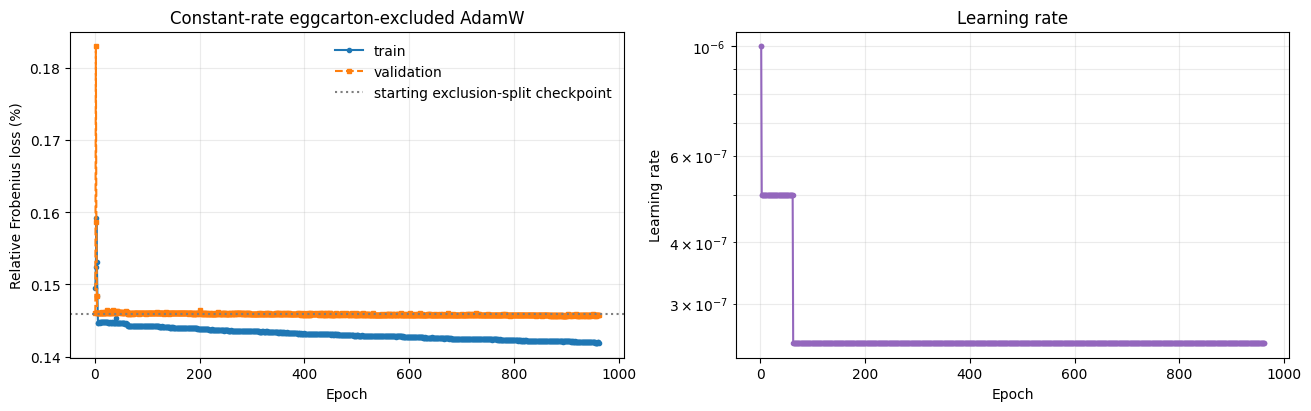

Synchronized 2026-09-04 07:47:19 UTC


In [ ]:
# Track one selected run. Set CUT_CELL_TRACKED_RUN before opening the notebook, or use the configured TRAINING run.
from clean_simulation.scripts.operations.training_control import build_run_status_script, synchronize_training_log

TRACKED_RUN = os.environ.get("CUT_CELL_TRACKED_RUN", TRAINING["run_name"] if "TRAINING" in globals() else "")
TRACKED_BASELINE = os.environ.get("CUT_CELL_TRACKED_BASELINE", "")
if not TRACKED_RUN:
    raise RuntimeError("Set CUT_CELL_TRACKED_RUN or run the training configuration cell first.")
baseline = float(TRACKED_BASELINE) if TRACKED_BASELINE else None

run_state, pid = remote_shell(build_run_status_script(SETTINGS, TRACKED_RUN), timeout=90).stdout.strip().splitlines()
print(f"Tracking {TRACKED_RUN} ({run_state.lower()}, PID {pid}).")

tracked_log = LOCAL_CACHE_ROOT / TRACKED_RUN / "training.log"
copied = synchronize_training_log(SETTINGS, TRACKED_RUN, tracked_log)
if copied.returncode:
    raise RuntimeError(copied.stderr.strip() or f"Could not synchronize {TRACKED_RUN}.")
log_text = tracked_log.read_text(encoding="utf-8", errors="replace")
for line in log_text.splitlines():
    if line.startswith("Excluded ") or "Starting transformer" in line:
        print(line)
rows = [
    {"epoch": int(epoch), "train_loss": float(train), "val_loss": float(validation), "learning_rate": float(lr), "seconds": float(seconds)}
    for epoch, train, validation, lr, seconds in re.findall(
        r"Epoch\s+(\d+)\s*/\s*\d+\s+\| Train: ([0-9.eE+-]+) \| Val: ([0-9.eE+-]+).*?Lr: ([0-9.eE+-]+) \| Time: ([0-9.eE+-]+)s", log_text,
    )
]
history = pd.DataFrame(rows)
if history.empty:
    print("No completed validation epoch yet.")
else:
    history = history.drop_duplicates("epoch", keep="last").sort_values("epoch")
    best = history.loc[history.val_loss.idxmin()]
    summary = {
        "state": run_state.lower(),
        "completed epoch": int(history.epoch.max()),
        "latest validation": history.val_loss.iloc[-1],
        "best validation": best.val_loss,
        "best epoch": int(best.epoch),
        "latest LR": history.learning_rate.iloc[-1],
    }
    if baseline is not None:
        summary["change from baseline (bp)"] = (best.val_loss - baseline) * 10000
    display(pd.DataFrame([summary]).style.format({
        "latest validation": "{:.4%}", "best validation": "{:.4%}",
        "change from baseline (bp)": "{:+.3f}", "latest LR": "{:.2e}",
    }))
    figure, (loss_axis, lr_axis) = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    loss_axis.plot(history.epoch, 100 * history.train_loss, marker="o", markersize=3, label="train")
    loss_axis.plot(history.epoch, 100 * history.val_loss, marker="s", markersize=3, linestyle="--", label="validation")
    if baseline is not None:
        loss_axis.axhline(100 * baseline, color="tab:gray", linestyle=":", label="baseline")
    loss_axis.set(title=f"{TRACKED_RUN}: convergence", xlabel="Epoch", ylabel="Relative Frobenius loss (%)")
    loss_axis.grid(True, alpha=0.25); loss_axis.legend(frameon=False)
    lr_axis.semilogy(history.epoch, history.learning_rate, marker="o", markersize=3, color="tab:purple")
    lr_axis.set(title="Learning rate", xlabel="Epoch", ylabel="Learning rate")
    lr_axis.grid(True, which="both", alpha=0.25)
    plt.show()
print(f"Synchronized {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S UTC')}")